In [1]:
import numpy as np
import scipy as sp
import matplotlib.pyplot as plt
import sympy as sm

In [2]:
########## Problem 1

# definitions from the problem

d = 2.35
a = 4 * d / np.sqrt(3)
eps_s = -14.79
eps_p = -7.59
h2m = 7.619964

Vsss = -1.4 * h2m / d**2
Vsps = 1.84 * h2m / d**2
Vpps = 3.24 * h2m / d**2
Vppp = -0.81 * h2m / d**2

del_1 = a / 4 * np.array([1,1,1])
del_2 = a / 4 * np.array([1,-1,-1])
del_3 = a / 4 * np.array([-1,1,-1])
del_4 = a / 4 * np.array([-1,-1,1])

def t(ux, uy, uz):
    return np.array([
        [Vsss, Vsps * ux, Vsps * uy, Vsps * uz],
        [-Vsps * ux, Vppp + (Vpps - Vppp) * ux * ux, (Vpps - Vppp) * ux * uy, (Vpps - Vppp) * ux * uz],
        [-Vsps * uy, (Vpps - Vppp) * uy * ux, Vppp + (Vpps - Vppp) * uy * uy, (Vpps - Vppp) * uy * uz],
        [-Vsps * uz, (Vpps - Vppp) * uz * ux, (Vpps - Vppp) * uz * uy, Vppp + (Vpps - Vppp) * uz * uz]
    ])

In [3]:
# task A

# For this task, I just make the T(k) and h0 matrices as given in the problem, and then combine them into the full hamiltonian. The signs of s-p and p-s swap 
# since when you move the p orbital around to the other side of the s orbital, the sign that approaches the s orbital is different. 

del_list = [del_1, del_2, del_3, del_4]

def T(k):
    T_matrix = np.zeros((4,4), dtype = complex)

    for dels in del_list:
        ux, uy, uz = dels / d
        T_matrix += t(ux, uy, uz) * np.exp(1j * np.dot(k, dels) )

    return T_matrix

h0 = np.diag([eps_s, eps_p, eps_p, eps_p])

def H_matrix(k):
    return np.block([
        [h0, T(k)],
        [T(k).conj().T, h0]
    ])

In [4]:
# task B

# Since xi isn't given, numpy will not be able to diagonalize. For this reason, I imported sympy and then remade the matrices using xi instead of k in the sympy
# format. To blockwise diagonalize, I group the basis as s_A, py_A, s_B, py_B, px_A, pz_A, px_B, pz_B where the first 4 are impacted by xi (along the y axis) and
# the rest aren't. 

xi = sm.symbols("xi", real = True)

def T_sm(xi):
    k = (2 * sm.pi / a) * sm.Matrix([0, xi, 0])
    T_matrix = sm.zeros(4,4)

    for dels in del_list:
        ux, uy, uz = dels / d
        T_matrix += sm.Matrix(t(ux, uy, uz)) * sm.exp(sm.I * k.dot(sm.Matrix(dels)))

    return sm.simplify(T_matrix)

h0_sm = sm.Matrix(h0)

def H_matrix_sm(xi):
    return sm.BlockMatrix([
        [h0_sm, T_sm(xi)],
        [T_sm(xi).conjugate().T, h0_sm]
    ]).as_explicit()

order = [0, 2, 4, 6, 1, 3, 5, 7]
H_reorder = H_matrix_sm(xi).extract(order, order)

display(H_reorder)

# from here, I have [[y axis, 0],[0, not y axis]], and I can diagonalize these. It's not pretty, but at least python didn't give up unlike when I tried the 8x8.

H_yaxis = H_reorder[:4, :4]
H_noty = H_reorder[4:, 4:]

yeigens = H_yaxis.eigenvals()
notyeigens = H_noty.eigenvals()

display(yeigens)
display(notyeigens)

Matrix([
[                            -14.79,                               0.0,   -7.72689875961974*cos(0.5*pi*xi), 5.86319558936864*I*sin(0.5*pi*xi),                                0.0,                                0.0,                                 0,                                 0],
[                               0.0,                             -7.59, -5.86319558936864*I*sin(0.5*pi*xi),   2.98037523585333*cos(0.5*pi*xi),                                0.0,                                0.0,                                 0,                                 0],
[  -7.72689875961974*cos(0.5*pi*xi), 5.86319558936864*I*sin(0.5*pi*xi),                             -14.79,                               0.0,                                  0,                                  0,                               0.0,                               0.0],
[-5.86319558936864*I*sin(0.5*pi*xi),   2.98037523585333*cos(0.5*pi*xi),                                0.0,                          

{Piecewise((-sqrt(-2*(-(0.0832620252414351*cos(1.0*pi*xi) - 94.5908630131422)**3/108 + (0.0832620252414351*cos(1.0*pi*xi) - 94.5908630131422)*(1712.11992660247*sin(0.5*pi*xi)**4 - 3396.23103500345*sin(0.5*pi*xi)**2 - 2057.752402998*cos(1.0*pi*xi) - 197.91783919047*cos(2.0*pi*xi) + 2065.07403253933)/3 - (182.960380421731*cos(1.0*pi*xi) + 182.96038042173)**2/8)**(1/3) - 0.0555080168276234*cos(1.0*pi*xi) + 63.0605753420948)/2 + sqrt((365.920760843462*cos(1.0*pi*xi) + 365.920760843461)/sqrt(-2*(-(0.0832620252414351*cos(1.0*pi*xi) - 94.5908630131422)**3/108 + (0.0832620252414351*cos(1.0*pi*xi) - 94.5908630131422)*(1712.11992660247*sin(0.5*pi*xi)**4 - 3396.23103500345*sin(0.5*pi*xi)**2 - 2057.752402998*cos(1.0*pi*xi) - 197.91783919047*cos(2.0*pi*xi) + 2065.07403253933)/3 - (182.960380421731*cos(1.0*pi*xi) + 182.96038042173)**2/8)**(1/3) - 0.0555080168276234*cos(1.0*pi*xi) + 63.0605753420948) + 2*(-(0.0832620252414351*cos(1.0*pi*xi) - 94.5908630131422)**3/108 + (0.0832620252414351*cos(1.0*pi*

{Piecewise((-sqrt(-2*(-(46.6338418690608*cos(1.0*pi*xi) - 64.3991149620364)**3/108 + (46.6338418690608*cos(1.0*pi*xi) - 64.3991149620364)*(3160.98060768108*sin(0.5*pi*xi)**4 - 5530.77651558809*sin(0.5*pi*xi)**2 - 2686.48702577704*cos(1.0*pi*xi) - 123.283175026563*cos(2.0*pi*xi) + 2888.67143282061)/3 - 6.46234853557053e-27)**(1/3) - 31.0892279127072*cos(1.0*pi*xi) + 42.9327433080243)/2 + sqrt(2*(-(46.6338418690608*cos(1.0*pi*xi) - 64.3991149620364)**3/108 + (46.6338418690608*cos(1.0*pi*xi) - 64.3991149620364)*(3160.98060768108*sin(0.5*pi*xi)**4 - 5530.77651558809*sin(0.5*pi*xi)**2 - 2686.48702577704*cos(1.0*pi*xi) - 123.283175026563*cos(2.0*pi*xi) + 2888.67143282061)/3 - 6.46234853557053e-27)**(1/3) - 62.1784558254145*cos(1.0*pi*xi) + 85.8654866160486 + 4.54747350886464e-13/sqrt(-2*(-(46.6338418690608*cos(1.0*pi*xi) - 64.3991149620364)**3/108 + (46.6338418690608*cos(1.0*pi*xi) - 64.3991149620364)*(3160.98060768108*sin(0.5*pi*xi)**4 - 5530.77651558809*sin(0.5*pi*xi)**2 - 2686.48702577704

In [5]:
# task C

# first I will print the hoppings + gamma and chi energies from diagonalizing

print("Hopping parameters (eV)")
print("Vsss:", Vsss)
print("Vsps:", Vsps)
print("Vpps:", Vpps)
print("Vppp:", Vppp)

k_gamma = (2 * np.pi / a) * np.array([0,0,0])
k_chi = (2 * np.pi / a) * np.array([0,1,0])

E_gamma = np.linalg.eigvalsh(H_matrix((k_gamma)))
E_chi = np.linalg.eigvalsh(H_matrix((k_chi)))

print(f"{'Band':<10}{'Gamma (eV)':<20}{'X (eV)':<20}")

for i in range(8):
    print(f"{i+1:<10}{E_gamma[i]:<20f}{E_chi[i]:<20f}")

# Before finding the max difference between analytic eigenvalues and those from diagonalizing, I need to make the analytic equations compatible with the 
# np.linspace using lambdify, and then I just calculate at each chi and compare the difference. Notably the analytic eigenvalues need to be sorted before
# comparing, as the diagonalized ones are automatically sorted from least to greatest. 

xi_space = np.linspace(0, 1, 801)

analytic_eigens = []

for E, multiplicity in list(yeigens.items()):
    analytic_eigens.extend([E] * multiplicity)

for E, multiplicity in list(notyeigens.items()):
    analytic_eigens.extend([E] * multiplicity)

analytic_funcs = [sm.lambdify(xi, E, "numpy") for E in analytic_eigens]

max_diff = 0

for i in range(len(xi_space)):
    diag_energy = np.linalg.eigvalsh(H_matrix((2 * np.pi / a) * np.array([0,xi_space[i],0])))
    numer_energy = np.array([f(complex(xi_space[i])) for f in analytic_funcs], dtype = complex)
    numer_energy = np.sort(numer_energy)
    diff = np.max(np.abs(diag_energy - numer_energy))
    if diff > max_diff:
        max_diff = diff

print("Max difference (eV):", max_diff)

Hopping parameters (eV)
Vsss: -1.931724689904934
Vsps: 2.5388381638750563
Vpps: 4.470562853779991
Vppp: -1.1176407134449977
Band      Gamma (eV)          X (eV)              
1         -22.516899          -18.070193          
2         -10.570375          -18.070193          
3         -10.570375          -15.040938          
4         -10.570375          -15.040938          
5         -7.063101           -4.309807           
6         -4.609625           -4.309807           
7         -4.609625           -0.139062           
8         -4.609625           -0.139062           
Max difference (eV): 3.332000937312536e-07


Minimum direct gap (eV): 3.5072739954730654
Location: 0.0


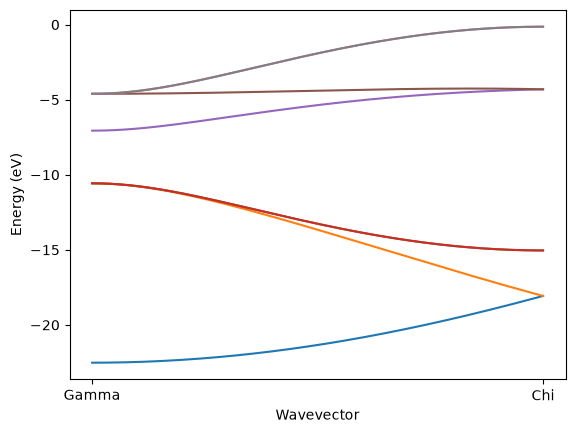

In [6]:
# task D

# to plot the bands, I'll just reuse the xi_space and apply it to the diagonalized hamiltonian to get energies, then just plot those energies. 

bands = []

for i in range(len(xi_space)):
    energy = np.linalg.eigvalsh(H_matrix((2 * np.pi / a) * np.array([0,xi_space[i],0])))
    bands.append(energy)

bands = np.array(bands)

for i in range(8):
    plt.plot(xi_space, bands[:, i])

plt.xticks([0, 1], ["Gamma", "Chi"])
plt.xlabel("Wavevector")
plt.ylabel("Energy (eV)")
plt.savefig("problem1_taskD_graph.png", dpi = 600)

# Since the graph shows a direct gap, I just loop through the difference between the top valence band and bottom conduction band. Unlike finding max
# differences, I can't just start at 0 and check for something increasing. I chose 10 as a starting min gap because it's pretty obvious by looking at
# the graph that the gap will be less than that. 

min_gap = 10
min_xi = 0

for i in range(len(xi_space)):
    gap = bands[i, 4] - bands[i, 3]
    if gap < min_gap:
        min_gap = gap
        min_xi = xi_space[i]

print("Minimum direct gap (eV):", min_gap)
print("Location:", min_xi)

# In the tight binding model, silicon's conduction bands aren't represented well enough by the four valence orbitals on each atom, though I can't
# confidently say why. Adding an s* orbital allows the conduction bands to couple a bit differently, and in a more accurate to life way, but the
# textbook doesn't go into too much detail outside of that. 

In [10]:
########## Problem 2

# definitions from the problem

a = 5.65
d = np.sqrt(3) * a / 4

eps_ga_s = -11.55
eps_ga_p = -5.67
eps_as_s = -18.92
eps_as_p = -8.98

l_ga = 0.058
l_as = 0.14

Lx = np.array([
    [0,0,0],
    [0,0,-1j],
    [0,1j,0]
])

Ly = np.array([
    [0,0,1j],
    [0,0,0],
    [-1j,0,0]
])

Lz = np.array([
    [0,-1j,0],
    [1j,0,0],
    [0,0,0]
])

sigmax = np.array([
    [0,1],
    [1,0]
])

sigmay = np.array([
    [0,-1j],
    [1j,0]
])

sigmaz = np.array([
    [1,0],
    [0,-1]
])

Lx_ga = np.zeros((8, 8), dtype = complex)
Ly_ga = np.zeros((8, 8), dtype = complex)
Lz_ga = np.zeros((8, 8), dtype = complex)

Lx_as = np.zeros((8, 8), dtype = complex)
Ly_as = np.zeros((8, 8), dtype = complex)
Lz_as = np.zeros((8, 8), dtype = complex)

Lx_ga[1:4, 1:4] = Lx
Ly_ga[1:4, 1:4] = Ly
Lz_ga[1:4, 1:4] = Lz

Lx_as[5:8, 5:8] = Lx
Ly_as[5:8, 5:8] = Ly
Lz_as[5:8, 5:8] = Lz

H_so = (l_ga * (np.kron(sigmax, Lx_ga) + np.kron(sigmay, Ly_ga) + np.kron(sigmaz, Lz_ga)) + l_as * (np.kron(sigmax, Lx_as) + np.kron(sigmay, Ly_as) + np.kron(sigmaz, Lz_as)))


In [37]:
# task A

# Since the h0 is replaced with h_ga and h_as, I need to rebuild the H matrix a little bit. Since we're considering the matrix at the gamma point, I can reuse
# the k_gamma made earlier. 

h_ga = np.diag([eps_ga_s, eps_ga_p, eps_ga_p, eps_ga_p])
h_as = np.diag([eps_as_s, eps_as_p, eps_as_p, eps_as_p])

def H_matrix_2(k):
    return np.block([
        [h_ga, T(k)],
        [T(k).conj().T, h_as]
    ])

H_gamma = H_matrix_2(k_gamma)

display(sm.simplify(H_gamma))

# from this hamiltonian, I can get the s block matrix and 3 identitcal p block matrices. 

H_s = H_gamma[np.ix_([0, 4], [0, 4])]
H_px = H_gamma[np.ix_([1, 5], [1, 5])]
H_py = H_gamma[np.ix_([2, 6], [2, 6])]
H_pz = H_gamma[np.ix_([3, 7], [3, 7])]

display(sm.simplify(H_s))
display(sm.simplify(H_px))
display(sm.simplify(H_py))
display(sm.simplify(H_pz))

# last, I just get the analytic eigenvalues from these matrices. For a 2x2 hermitian matrix, the eigenvalues are easily found with some paper, but I'll get them
# symbolically. Even though the p matrices are identical, I'll run them all separately for the sake of completion.

A = sm.symbols("A")
B = sm.symbols("B")
C = sm.symbols("C")
analytical2x2 = sm.Matrix([[A,B], [B,C]])
analytic_eigenvals2x2 = analytical2x2.eigenvals()
display(analytic_eigenvals2x2)

energy_s = [E.subs({A: H_s[0,0], B: H_s[1,0], C: H_s[1,1]}) for E in analytic_eigenvals2x2]
energy_px = [E.subs({A: H_px[0,0], B: H_px[1,0], C: H_px[1,1]}) for E in analytic_eigenvals2x2]
energy_py = [E.subs({A: H_py[0,0], B: H_py[1,0], C: H_py[1,1]}) for E in analytic_eigenvals2x2]
energy_pz = [E.subs({A: H_pz[0,0], B: H_pz[1,0], C: H_pz[1,1]}) for E in analytic_eigenvals2x2]

print("s energies (ev):", energy_s)
print("px energies (eV):", energy_px)
print("py energies (eV):", energy_py)
print("pz energies (eV):", energy_pz)

[[-11.55, 0, 0, 0, -7.72689875961974, 0, 0, 0], [0, -5.67, 0, 0, 0, 2.40405420941995, 0, 0], [0, 0, -5.67, 0, 0, 0, 2.40405420941995, 0], [0, 0, 0, -5.67, 0, 0, 0, 2.40405420941995], [-7.72689875961974, 0, 0, 0, -18.92, 0, 0, 0], [0, 2.40405420941995, 0, 0, 0, -8.98, 0, 0], [0, 0, 2.40405420941995, 0, 0, 0, -8.98, 0], [0, 0, 0, 2.40405420941995, 0, 0, 0, -8.98]]

[[-11.55, -7.72689875961974], [-7.72689875961974, -18.92]]

[[-5.67, 2.40405420941995], [2.40405420941995, -8.98]]

[[-5.67, 2.40405420941995], [2.40405420941995, -8.98]]

[[-5.67, 2.40405420941995], [2.40405420941995, -8.98]]

{A/2 + C/2 - sqrt(A**2 - 2*A*C + 4*B**2 + C**2)/2: 1,
 A/2 + C/2 + sqrt(A**2 - 2*A*C + 4*B**2 + C**2)/2: 1}

s energies (ev): [-23.7956185197924, -6.67438148020758]
px energies (eV): [-10.2436472280544, -4.40635277194558]
py energies (eV): [-10.2436472280544, -4.40635277194558]
pz energies (eV): [-10.2436472280544, -4.40635277194558]


In [51]:
# task B

# to make the spin orbit hamiltonian, I take a direct product of the identity matrix and non SO matrix, then add the spin orbit coupled part from the defined one above.

def H_spin(k):
    return np.kron(np.eye(2), H_matrix_2(k)) + H_so

# the isolated p shell is from one atom, so we can get it by cutting the previous H_so to not consider the lambda parts. We see that, if we were to multiply by lambda, we
# would have two -2lambda and four +1lambda. 

H_so_ponly = (np.kron(sigmax, Lx) + np.kron(sigmay, Ly) + np.kron(sigmaz, Lz))

print("p shell eigenvalues (eV):", np.linalg.eigvalsh(H_so_ponly))

# For j = 1/2, there are 2 states +-1/2, so that will be the doublet and for j = 3/2, there are 4 states +-3/2 and +-1/2, so that will be the quadruplet. So the side blocks
# for j = 1/2 are the p matrices -2 lambda and for j = 3/2, p matrices + lambda. The eigenvalues are evaluated, and if we compared to the eigenvalues of the 16x16, we see 
# that they are in there along with the additional eigenvalues from the s orbital.

H_12 = H_px - 2 * np.diag([l_ga, l_as])
H_32 = H_px + np.diag([l_ga, l_as])

print("j = 1/2 energy (eV):", np.linalg.eigvalsh(H_12))
print("j = 3/2 energy (eV):", np.linalg.eigvalsh(H_32))

energy16x16 = np.linalg.eigvalsh(H_spin(k_gamma))
print("16x16 eigenvalues (eV):", energy16x16)

p shell eigenvalues (eV): [-2. -2.  1.  1.  1.  1.]
j = 1/2 energy (eV): [-10.48891396  -4.55708604]
j = 3/2 energy (eV): [-10.12159539  -4.33040461]
16x16 eigenvalues (eV): [-23.79561852 -23.79561852 -10.48891396 -10.48891396 -10.12159539
 -10.12159539 -10.12159539 -10.12159539  -6.67438148  -6.67438148
  -4.55708604  -4.55708604  -4.33040461  -4.33040461  -4.33040461
  -4.33040461]


In [66]:
# task C

# If I want to find the direct gaps, I need to look at the separation of the middle bands for both spin orbit coupled and non coupled. 

bands_noSO = np.linalg.eigvalsh(H_matrix_2(k_gamma))
bands_SO = np.linalg.eigvalsh(H_spin(k_gamma))

gap_noSO = bands_noSO[4] - bands_noSO[3]
gap_SO = bands_SO[8] - bands_SO[7]

print("No spin orbit coupling direct band gap at gamma (eV):", gap_noSO)
print("Spin orbit coupled direct band gap at gamma (eV):", gap_SO)

# for the valence split-off separation, I look at the lowest eigenvalues of the j = 3/2 and 1/2 that I found in the last task

print("Valence split-off separation (eV):", np.linalg.eigvalsh(H_32)[0] - np.linalg.eigvalsh(H_12)[0])

# to get gallium weight, I find the eigenvectors alongside the eigenvalues. Since the matrix is organized as 4 ga with some spin, 4 as with some spin, 4 ga with other spin,
# 4 as with other spin, I need to pull out just the gallium parts. From there, I sum their probabilities and take the average. 

energies_spin, vectors_spin = np.linalg.eigh(H_spin(k_gamma))

val_vecs = vectors_spin[:, 4:8]

needed_vecs = [0,1,2,3,8,9,10,11]
weights = 0
for i in needed_vecs:
    weights += np.abs(val_vecs[i]**2)

print("Mean gallium weight:", np.mean(weights))

No spin orbit coupling direct band gap at gamma (eV): 3.569265747846848
Spin orbit coupled direct band gap at gamma (eV): 3.447213906207751
Valence split-off separation (eV): 0.3673185775812211
Mean gallium weight: 0.2213008406540383


Random point 1: [ 0.69175451 -1.10487805  0.2138013 ]
H - H_dagger max difference: 0.0
E(k) - E(-k) max difference(eV): 1.4210854715202004e-14
Random point 2: [-0.81187364  0.57337492  0.49616289]
H - H_dagger max difference: 0.0
E(k) - E(-k) max difference(eV): 2.4868995751603507e-14
Random point 3: [-0.47374336 -0.31681306 -0.97725136]
H - H_dagger max difference: 0.0
E(k) - E(-k) max difference(eV): 1.0658141036401503e-14
Random point 4: [-0.52493147 -0.01628795  0.5086321 ]
H - H_dagger max difference: 0.0
E(k) - E(-k) max difference(eV): 7.105427357601002e-15
Random point 5: [0.46599883 0.7826134  0.27145145]
H - H_dagger max difference: 0.0
E(k) - E(-k) max difference(eV): 1.0658141036401503e-14
Random point 6: [-0.89258371 -0.92116221 -0.20628759]
H - H_dagger max difference: 0.0
E(k) - E(-k) max difference(eV): 1.5987211554602254e-14
Random point 7: [ 0.96456844 -0.59872311 -0.07355356]
H - H_dagger max difference: 0.0
E(k) - E(-k) max difference(eV): 7.105427357601002e-15
Rand

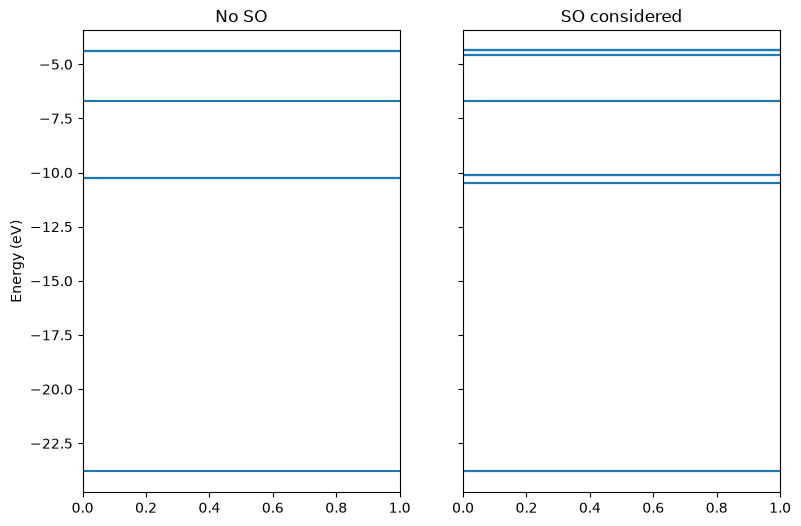

In [84]:
# task D

# I can make a gamma level comparison by plotting the energies on a 2 panel graph. 

fig, ax = plt.subplots(1, 2, figsize=(9, 6), sharey=True)

for E in bands_noSO:
    ax[0].axhline(E)

for E in bands_SO:
    ax[1].axhline(E)

ax[0].set_title("No SO")
ax[1].set_title("SO considered")
ax[0].set_ylabel("Energy (eV)")
plt.savefig("problem2_taskD_graph.png", dpi = 600)

# to verify hermiticity at 10 random points, I just generate 10 points and then subtract the matrix from its hermitian conjugate. Since the max differences are 0, the hermiticity
# is confirmed. Same thing goes for checking the energies of k and -k. They aren't 0, but on the order of 10^-14 is machine error. 

for i in range(10):
    k = (2 * np.pi / a) * np.array([np.random.uniform(-1,1),np.random.uniform(-1,1),np.random.uniform(-1,1)])
    print(f"Random point {i+1}:", k)
    print("H - H_dagger max difference:", np.max(np.abs(H_spin(k)) - np.abs(H_spin(k).conj().T)))
    print("E(k) - E(-k) max difference(eV):", np.max(np.abs(np.linalg.eigvalsh(H_spin(k))) - np.abs(np.linalg.eigvalsh(H_spin(-k)))))

# Time reversal means opposite momentum, not the same momentum. So it's not a requirement from time reversal specifically to have degeneracy at any particular momentum. The experimental
# band gap for GaAs is approximately 1.42 eV, compared to my calculated one of roughly 3.44 eV. Like with anything in these computations, we are making approximations, so we aren't necessarily
# expecting agreement between ALL experimental results at all times, just sometimes. Now if nothing we ever find agrees with experiment, then either everything is being calculated wrong,
# or the approximations we are using are too extreme and need to be changed. 